In [893]:
from em1d.experiment import *
import matplotlib.pyplot as plt
import numpy as np

In [894]:
tx = Loop(x=torch.tensor([-25, 25]), y=torch.tensor([-25, -25]), z=torch.tensor([0, 0]))

In [895]:
class Forward1:
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        if self.rmin==0: self.rmin = 1e-2
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()
        self.pfield_dz = np.abs(self.srcz-self.rz)[0]
        self.sfield_dz = np.abs(self.srcz)+np.abs(self.rz)[0]
        self.device = torch.device('cpu')
        self.tolerance=tolerance        

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            cRTE = rte(self.sigma, self.thick, self.omega, lmb)
            intg = np.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*np.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return np.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), smp_per_decade=10)
        res = integrate_around_loop(self.source, self.receiver, hkl1)
        return res.squeeze()

    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward()

In [1148]:
class Forward2:
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        if self.rmin==0: self.rmin = 1e-2
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()
        self.pfield_dz = np.abs(self.srcz-self.rz)[0]
        self.sfield_dz = np.abs(self.srcz)+np.abs(self.rz)[0]
        self.device = torch.device('cpu')
        self.tolerance=tolerance        

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            cRTE = rte(self.sigma, self.thick, self.omega, lmb)
            intg = np.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*np.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return np.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10)
        r,HR = hkl1.range(self.rmin, self.rmax)
        sofr = s_of_r2(self.source, self.receiver, r)
        res = torch.einsum('...i,...i->...', HR, sofr)
        # cbr = CubicSpline(r, HR*sofr)
        # res = cbr.integrate(self.rmin, self.rmax)
        
        return res, (r, HR, sofr)
    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward()

In [1164]:
def r_edges(r):
    dR_alpha = torch.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

def s_of_r2(self, rx, R):
    """almost working"""
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
        R_ = R
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r_perp = torch.abs(y1)
        
       
        Rp1 = torch.sqrt(x1**2 + y1**2)
        Rp2 = torch.sqrt(x2**2 + y2**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        dx_comp = R_*(R_edge2-R_edge1) / (R_**2 - r_perp**2)**(1/2)
        # this is necessary to avoid nan values in the dx_comp
        dx_comp[R_<=r_perp] = 1.
        Rcomp = 1.

        maskx = (x1>=0)*(x2>=0)
        maskr = (R_edge2>=Rp1)*(R_edge1<=Rp2)
    
        ds[maskx*maskr] += (dx_comp*Rcomp)[maskx*maskr]
        # dx_comp[maskx*maskr] = 0.

        maskx = (x1<0)*(x2>0)
        maskxleft = x1+x2<0
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp1)
        
        # Rcomp = (Rp1/R_)
        ds[maskx*maskxleft*maskr] += (dx_comp*Rcomp)[maskx*maskxleft*maskr]
        # dx_comp[maskx*maskr*maskxleft] = 0.

        
        maskxright = x1+x2>=0
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp2)
        
        # Rcomp = (Rp2/R_)
        ds[maskx*maskxright*maskr] += (dx_comp*Rcomp)[maskx*maskxright*maskr]

        maskx = (x1<=0)*(x2<=0)
        maskr = (R_edge2>=Rp2)*(R_edge1<=Rp1)
        ds[maskx*maskr] += (dx_comp*Rcomp)[maskx*maskr]
        # dx_comp[maskx*maskr] = 0.
        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        
        # cbr = CubicSpline(R, ds)
        # ds_sum = cbr.integrate(R.min(), R.max())[..., None]


        
        if ds_sum.sum()==0:
            print('ds==0\tr_perp is ', r_perp[0].item())
        ds *= s_norm/ds_sum
        Rcomp = (R_**2 + 0.25*ds**2)**(1/2)

        s += torch.nan_to_num((y1*ds)/(Rcomp))#*Rcomp
        # s += torch.nan_to_num(ds)
    return s#.real

In [1234]:
def r_edges(r):
    dR_alpha = torch.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

def s_of_r2(self, rx, R):
    """almost working"""
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = R_edge2-R_edge1
    iR = torch.arange(len(R))
    
    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
        R_ = R
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        iR = iR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_lb = R_*1.
        R_lb[..., 1:] = R_[..., :-1]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r_perp = torch.abs(y1)
        
       
        Rp1 = torch.sqrt(x1**2 + y1**2)
        Rp2 = torch.sqrt(x2**2 + y2**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        
        rmax = torch.sqrt(r_perp**2+x1**2)
        rmin = r_perp

        cx = np.sqrt(torch.abs(R_**2 - r_perp**2))
        dx = torch.diff(cx, axis=-1, prepend=torch.zeros_like(cx[..., 0:1]))
        # dx = R_*(R_-R_lb) / (R_**2 - r_perp**2)**(1/2)
        dx[R_<r_perp] = 0
        dx[R_>rmax] = 0
        ir1 = torch.searchsorted(R_, rmin)
        ir2 = torch.searchsorted(R_, rmax)-1

        
        dx[ir1==iR]=cx[ir1==iR]
        dx[ir2==iR] += x1[ir2==iR]-cx[ir2==iR]


        ds1 = dx*1.
        ds1 *= torch.abs(x1)/torch.abs(torch.nansum(ds1, axis=-1, keepdims=True))
        Rcomp = (R_**2 - (0.25*ds1)**2)**(1/2)
        # ds1 /= R_/Rcomp

        rmax = torch.sqrt(r_perp**2+x2**2)

        cx = np.sqrt(torch.abs(R_**2 - r_perp**2))
        dx = torch.diff(cx, axis=-1, prepend=torch.zeros_like(cx[..., 0:1]))
        # dx = R_*(R_-R_lb) / (R_**2 - r_perp**2)**(1/2)
        dx[R_<r_perp] = 0
        dx[R_>rmax] = 0


        ir1 = torch.searchsorted(R_, rmin)
        ir2 = torch.searchsorted(R_, rmax)-1

        dx[ir1==iR]=(cx[ir1==iR])
        dx[ir2==iR] += x2[ir2==iR]-cx[ir2==iR]


        ds2  = dx*1.
        ds2 *= torch.abs(x2)/torch.abs(torch.nansum(ds2, axis=-1, keepdims=True))
        Rcomp = (R_**2 - (0.25*ds2)**2)**(1/2)
        # ds2 /= R_/Rcomp

        ds = ds1 + ds2

        # ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        # ds *= s_norm/ds_sum
        s += torch.nan_to_num(y1*ds/(R_))
    return s#.real

In [1235]:
# tx = Loop.square(25)
tx = Loop(x=torch.tensor([-25, 25]), y=torch.tensor([-25, -25]), z=torch.tensor([0, 0]))
sigma,thick = np.array([0.02, 0.1]), np.array([40])
bz1 = []
# ry = np.linspace(-50, 150, 260)
ry = np.linspace(0, 50, 50)
rxs = Receiver(y=-ry)
rx = Receiver()
fwr1 = Forward1(tx, rx, 2000)
bz1.append(fwr1(sigma, thick).item())

for yobs in ry[1:]:
    rx = Receiver(y=-yobs)
    # rx = Receiver()
    fwr1 = Forward1(tx, rx, 2000)
    bz1.append(fwr1(sigma, thick).item())
bz0 = np.array(bz1)
bz1 = bz0

In [1236]:
fwr2 = Forward2(tx, rxs, 2000)
bz2, (r, HR, sofr) = fwr2(sigma, thick)
bz2 = bz2.numpy()

C:\Users\au646858\AppData\Local\Temp\ipykernel_18108\2281498271.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


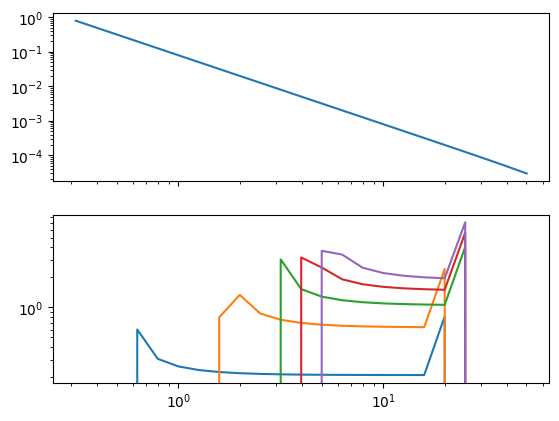

In [1237]:
rslice = slice(25, 30)
fig,axs = plt.subplots(2,1, sharex=True)
axs[0].loglog(r, np.abs(HR).T)
axs[1].loglog(r, torch.abs(sofr[rslice].T))

(0.001, 3)

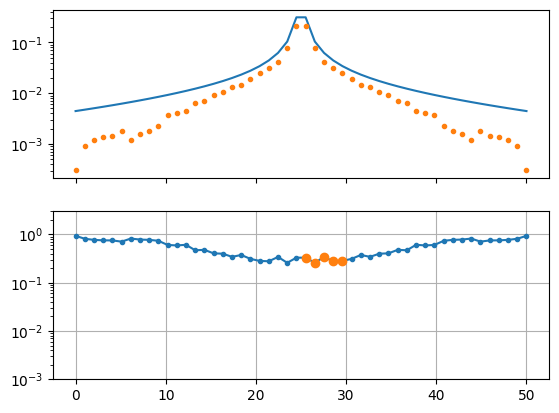

In [1238]:
dbz = np.abs(np.abs(bz1.real)-np.abs(bz2.real))/np.abs(bz1.real)
fig,axs = plt.subplots(2,1, sharex=True)
axs[0].semilogy(ry, np.abs(bz1), label='bz1')
axs[0].semilogy(ry, np.abs(bz2), '.', label='bz2')
axs[1].semilogy(ry, dbz, '.-', label='diff')
axs[1].semilogy(ry[rslice], dbz[rslice], 'o')

axs[1].grid()
axs[1].set_ylim(1e-3, 3)

10.0


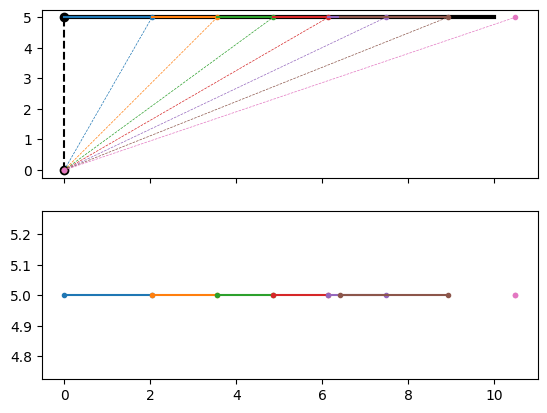

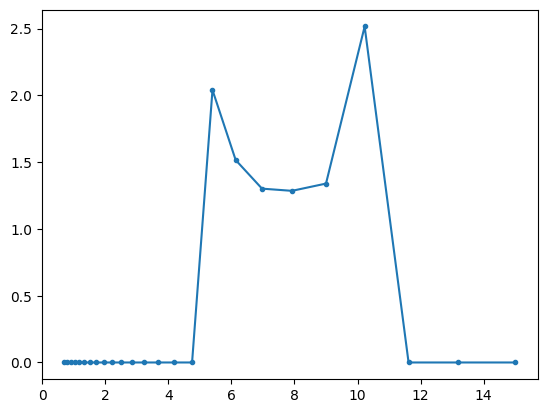

In [766]:
def r_edges(r):
    dR_alpha = np.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

rperp = 5#.1
x1 = 10
rmax = np.sqrt(rperp**2+x1**2)
rmin = rperp



fig,axs = plt.subplots(2,1, sharex=True)
axs[0].plot([0,0], [0, rperp], 'ko--')
axs[0].plot([0,x1], [rperp, rperp], 'k-', linewidth=3)

r = np.geomspace(0.7, 15, 25)
r_lb = np.insert(r[:-1], 0, 0)

x = np.sqrt(np.abs(r**2 - rperp**2))
dx = np.diff(x, prepend=0)

ir1 = np.searchsorted(r, rmin)
ir2 = np.searchsorted(r, rmax)

dx[:ir1] = 0
dx[ir1]=x[ir1]
dx[ir2:] = 0
dx[ir2-1] += x1-x[ir2-1]

print(dx.sum())


for i,R in enumerate(r):
    if i<ir1 or i>ir2: continue
    else:
        if R<=rperp:
            line = axs[0].plot([0, 0], [0, R], '.-')[0]
            axs[0].plot([0, dx[i]], [R, R], '-', color=line.get_color())
        else:
            cx = (R**2 - rperp**2)**(1/2)
            line = axs[0].plot([0, cx], [0, rperp], '.--', linewidth=0.5)[0]
            axs[0].plot([cx-dx[i], cx], [rperp, rperp], '-', color=line.get_color())
        
        if R<=rperp:
            axs[1].plot([0, dx[i]], [rperp, rperp], '.-')
        else:
            cx = (R**2 - rperp**2)**(1/2)
            axs[1].plot([cx-dx[i], cx], [rperp, rperp], '.-')


plt.figure()
plt.plot(r, dx, '.-')

22.0


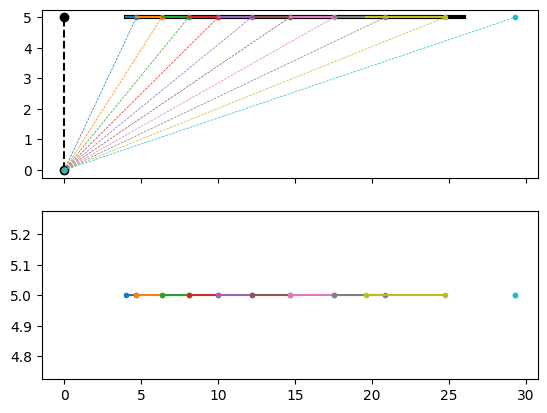

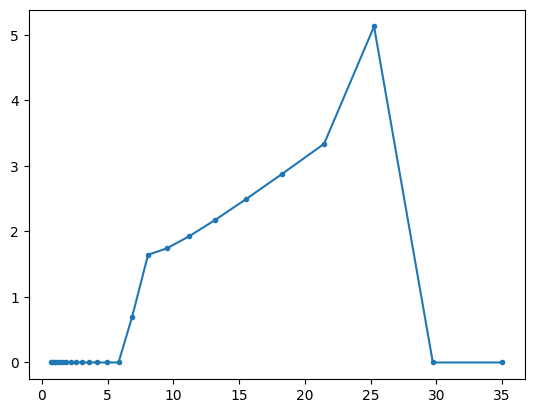

In [523]:
def r_edges(r):
    dR_alpha = np.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

rperp = 5#.1
x1,x2 = 4,26
rmax = np.sqrt(rperp**2+max(x1,x2)**2)
rmin = rperp
if np.sign(x1*x2)>0:
    rmin = np.sqrt(rperp**2+min(np.abs(x1),np.abs(x2))**2)
#    rmin = min(rmin, rperp)



fig,axs = plt.subplots(2,1, sharex=True)
axs[0].plot([0,0], [0, rperp], 'ko--')
axs[0].plot([x1,x2], [rperp, rperp], 'k-', linewidth=3)

r = np.geomspace(0.7, 35, 25)
r_lb = np.insert(r[:-1], 0, 0)

x = np.sqrt(np.abs(r**2 - rperp**2))
dx = np.diff(x, prepend=0)

ir1 = np.searchsorted(r, rmin)
ir2 = np.searchsorted(r, rmax)

dx[:ir1] = 0
dx[ir1]=x[ir1]-x1
dx[ir2:] = 0
dx[ir2-1] += x2-x[ir2-1]

print(dx.sum())


for i,R in enumerate(r):
    if i<ir1 or i>ir2: continue
    else:
        if R<=rperp:
            line = axs[0].plot([0, x1], [0, R], '.-')[0]
            axs[0].plot([0, dx[i]], [R, R], '-', color=line.get_color())
        else:
            cx = (R**2 - rperp**2)**(1/2)
            line = axs[0].plot([0, cx], [0, rperp], '.--', linewidth=0.5)[0]
            axs[0].plot([cx-dx[i], cx], [rperp, rperp], '-', color=line.get_color())
        
        if R<=rperp:
            axs[1].plot([x1, x1+dx[i]], [rperp, rperp], '.-')
        else:
            cx = (R**2 - rperp**2)**(1/2)
            axs[1].plot([cx-dx[i], cx], [rperp, rperp], '.-')


plt.figure()
plt.plot(r, dx, '.-')

5 13.0
16.0


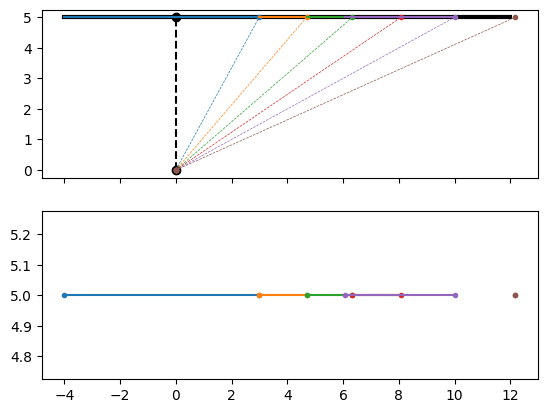

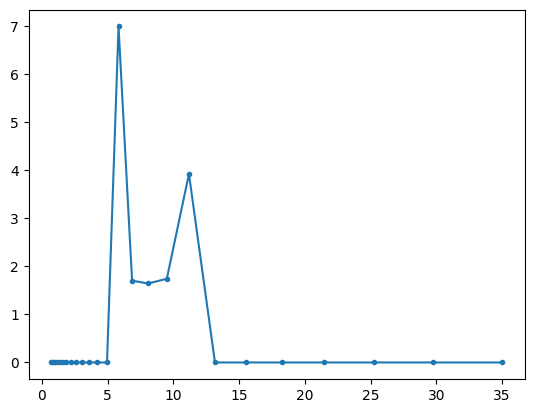

In [525]:
def r_edges(r):
    dR_alpha = np.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

rperp = 5#.1
x1,x2 = -4,12
rmax = np.sqrt(rperp**2+max(np.abs(x1),np.abs(x2))**2)
rmin = rperp
if np.sign(x1*x2)>0:
    rmin = np.sqrt(rperp**2+min(np.abs(x1),np.abs(x2))**2)
#    rmin = min(rmin, rperp)

print(rmin, rmax)

fig,axs = plt.subplots(2,1, sharex=True)
axs[0].plot([0,0], [0, rperp], 'ko--')
axs[0].plot([x1,x2], [rperp, rperp], 'k-', linewidth=3)

r = np.geomspace(0.7, 35, 25)
r_lb = np.insert(r[:-1], 0, 0)

x = np.sqrt(np.abs(r**2 - rperp**2))
dx = np.diff(x, prepend=0)

ir1 = np.searchsorted(r, rmin)
ir2 = np.searchsorted(r, rmax)

dx[:ir1] = 0
dx[ir1]=x[ir1]-x1
dx[ir2:] = 0
dx[ir2-1] += x2-x[ir2-1]

print(dx.sum())


for i,R in enumerate(r):
    if i<ir1 or i>ir2: continue
    else:
        if R<=rperp:
            line = axs[0].plot([0, x1], [0, R], '.-')[0]
            axs[0].plot([0, dx[i]], [R, R], '-', color=line.get_color())
        else:
            cx = (R**2 - rperp**2)**(1/2)
            line = axs[0].plot([0, cx], [0, rperp], '.--', linewidth=0.5)[0]
            axs[0].plot([cx-dx[i], cx], [rperp, rperp], '-', color=line.get_color())
        
        if R<=rperp:
            axs[1].plot([x1, x1+dx[i]], [rperp, rperp], '.-')
        else:
            cx = (R**2 - rperp**2)**(1/2)
            axs[1].plot([cx-dx[i], cx], [rperp, rperp], '.-')


plt.figure()
plt.plot(r, dx, '.-')